In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Simulação de dados de transações e volume de transações de clientes e-comemerce da Cielo.

np.random.seed(42)  # Reprodutibilidade

n = 365

data ={
    "Data": pd.date_range(start="2024-01-01", periods=n, freq="D"),
    "Cliente": np.random.choice(["A", "B", "C", "D", "F", "G", "H", "I", "J"], n),
    "Valor": np.random.normal(120, 80, n).round(2)

}

df = pd.DataFrame(data)
df.head()

,Data,Cliente,Valor
0,2024-01-01,H,13.85
1,2024-01-02,D,267.50
2,2024-01-03,I,61.54
3,2024-01-04,F,17.61
4,2024-01-05,H,101.01


In [ ]:
df['dia'] = df['Data'].dt.day
df['mes'] = df['Data'].dt.month
df['ano_mes']= df['Data'].dt.to_period('M')
#df['ano'] = df['Data'].dt.year
#df['hora'] = df['Data'].dt.hour
df.head()

,Data,Cliente,Valor,dia,mes,ano_mes
0,2024-01-01,H,13.85,1,1,2024-01
1,2024-01-02,D,267.50,2,1,2024-01
2,2024-01-03,I,61.54,3,1,2024-01
3,2024-01-04,F,17.61,4,1,2024-01
4,2024-01-05,H,101.01,5,1,2024-01


In [ ]:
# Explorando os dados: Criação de um dataframe com o valor total e o número de transações realizadas mensalmente pelos clientes.

analise = df.groupby('ano_mes').agg(total_valor =('Valor', 'sum'), transacoes = ('Valor', 'count')).reset_index()

analise

,ano_mes,total_valor,transacoes
0,2024-01,3975.62,31
1,2024-02,3714.17,29
2,2024-03,4028.65,31
3,2024-04,4082.79,30
4,2024-05,3983.66,31
5,2024-06,3923.93,30
6,2024-07,3342.99,31
7,2024-08,3555.40,31
8,2024-09,3105.65,30
9,2024-10,3808.08,31


In [ ]:
resultado = df.groupby('ano_mes').agg(
    media_valor=('Valor', 'mean'),
    mediana_valor=('Valor', 'median'),
    desvio_padrao_valor=('Valor', 'std'),
    transacoes_num=('Valor', 'count')
    ).reset_index()

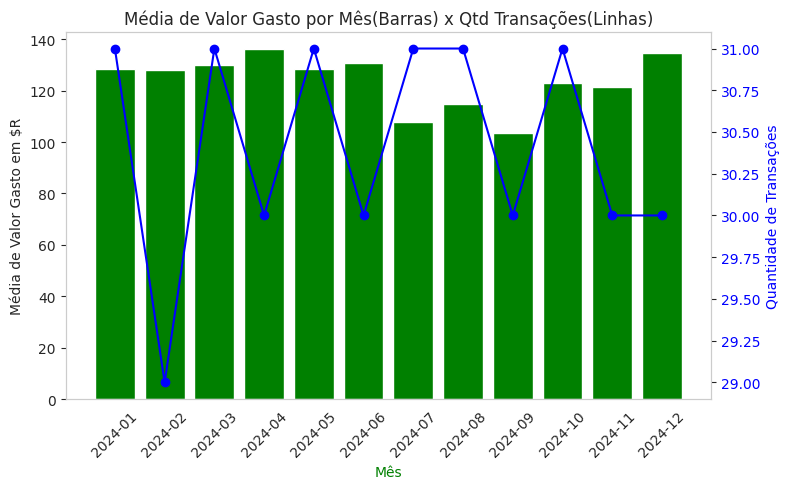

In [ ]:
media_por_mes = df.groupby('ano_mes')['Valor'].mean().reset_index()

# Plotar gráfico de barras

fig, ax1 = plt.subplots(figsize=(8, 5))

#Gráfico de Barras - media de valor gasto
ax1.bar(media_por_mes['ano_mes'].astype(str), media_por_mes['Valor'], color='green', label = 'Média de Valor Gasto')
ax1.set_xlabel("Mês", color = 'green')
ax1.set_ylabel("Média de Valor Gasto em $R")
plt.xticks(rotation=45)
fig.tight_layout()

#Criar segundo eixo para a quantidade de transições

ax2 = ax1.twinx()
ax2.plot(resultado['ano_mes'].astype(str), resultado['transacoes_num'], color='blue', marker='o', label = 'Quantidade de Transações')
ax2.set_ylabel("Quantidade de Transações", color='blue')
ax2.tick_params(axis='y', labelcolor='blue')

#handles1, labels1 = ax1.get_legend_handles_labels()
#handles2, labels2 = ax2.get_legend_handles_labels()
#ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper left')

#Titulo e ajustes
plt.title("Média de Valor Gasto por Mês(Barras) x Qtd Transações(Linhas)")
fig.tight_layout()
ax1.grid(False)
ax2.grid(False)
plt.show()

In [ ]:
#analise_por_cliente = df.groupby(['ano_mes', 'Cliente']).agg(total_valor =('Valor', 'sum'), valor_medio= ('Valor', 'mean'), transacoes = ('Valor', 'count')).reset_index()

analise_por_cliente = df.groupby(['Cliente']).agg(total_valor =('Valor', 'sum'), transacoes = ('Valor', 'count')).reset_index()

analise_por_cliente

,Cliente,total_valor,transacoes
0,A,5795.63,50
1,B,4042.47,33
2,C,5346.74,45
3,D,4971.19,38
4,F,4426.53,37
5,G,4745.62,36
6,H,5140.94,45
7,I,5596.51,43
8,J,5133.43,38


In [ ]:
analise_por_cliente['Maturidade']= analise_por_cliente.apply(
    lambda row: (
           'BaixaMaturidade' if row['transacoes'] <= 30 and (row['total_valor']) < 4000
        else 'MediaMaturidade' if row['transacoes'] <= 45 and (row['total_valor']) < 6000
        else 'AltaMaturidade'
    ),
    axis=1
)

analise_por_cliente

,Cliente,total_valor,transacoes,Maturidade
0,A,5795.63,50,AltaMaturidade
1,B,4042.47,33,MediaMaturidade
2,C,5346.74,45,MediaMaturidade
3,D,4971.19,38,MediaMaturidade
4,F,4426.53,37,MediaMaturidade
5,G,4745.62,36,MediaMaturidade
6,H,5140.94,45,MediaMaturidade
7,I,5596.51,43,MediaMaturidade
8,J,5133.43,38,MediaMaturidade


In [ ]:
resultado = df.groupby('ano_mes').agg(
    media_valor=('Valor', 'mean'),
    mediana_valor=('Valor', 'median'),
    desvio_padrao_valor=('Valor', 'std'),
    transacoes_num=('Valor', 'count')
    ).reset_index()

In [ ]:
resultado

,ano_mes,media_valor,mediana_valor,desvio_padrao_valor,transacoes_num
0,2024-01,128.245806,124.680,93.399647,31
1,2024-02,128.074828,120.970,66.105133,29
2,2024-03,129.956452,119.630,86.871114,31
3,2024-04,136.093000,150.750,85.750014,30
4,2024-05,128.505161,140.750,77.595987,31
5,2024-06,130.797667,133.445,80.597148,30
6,2024-07,107.838387,96.740,82.123215,31
7,2024-08,114.690323,105.050,87.914471,31
8,2024-09,103.521667,93.275,76.409114,30
9,2024-10,122.841290,127.150,90.482349,31


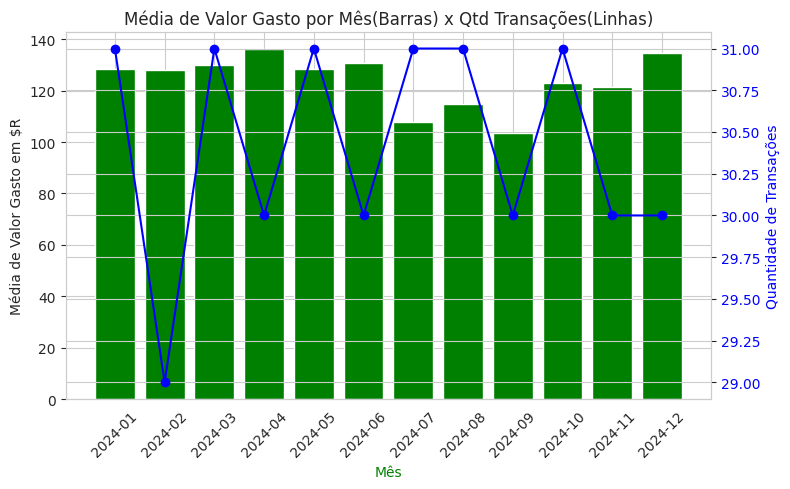

In [ ]:
media_por_mes = df.groupby('ano_mes')['Valor'].mean().reset_index()

# Plotar gráfico de barras

fig, ax1 = plt.subplots(figsize=(8, 5))

#Gráfico de Barras - media de valor gasto
ax1.bar(media_por_mes['ano_mes'].astype(str), media_por_mes['Valor'], color='green', label = 'Média de Valor Gasto')
ax1.set_xlabel("Mês", color = 'green')
ax1.set_ylabel("Média de Valor Gasto em $R")
plt.xticks(rotation=45)
fig.tight_layout()

#Criar segundo eixo para a quantidade de transições

ax2 = ax1.twinx()
ax2.plot(resultado['ano_mes'].astype(str), resultado['transacoes_num'], color='blue', marker='o', label = 'Quantidade de Transações')
ax2.set_ylabel("Quantidade de Transações", color='blue')
ax2.tick_params(axis='y', labelcolor='blue')

#handles1, labels1 = ax1.get_legend_handles_labels()
#handles2, labels2 = ax2.get_legend_handles_labels()
#ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper left')

#Titulo e ajustes
plt.title("Média de Valor Gasto por Mês(Barras) x Qtd Transações(Linhas)")
fig.tight_layout()
plt.show()

In [ ]:
#Treinar modelo
X = analise_por_cliente[['transacoes', 'total_valor']]
y = analise_por_cliente['Maturidade']

In [ ]:
modelo = RandomForestClassifier(random_state=42)
modelo.fit(X, y)

RandomForestClassifier(random_state=42)

In [ ]:
# ===== 3. Visualizar limites de decisão =====
# Criar grid de pontos para cobrir o espaço de valores
x_min, x_max = X['transacoes'].min() - 5, X['transacoes'].max() + 5
y_min, y_max = X['total_valor'].min() - 500, X['total_valor'].max() + 500
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

In [ ]:
Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
Z_cores = np.vectorize(cores.get)(Z)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
# Mapear cores para classes
cores = {
    'BaixaMaturidade': '#87CEFA',   # azul claro
    'MediaMaturidade': '#FFD700',   # amarelo
    'AltaMaturidade': '#FF6347'     # vermelho tomate
}
Z_cores = np.vectorize(cores.get)(Z)

TypeError: Image data of dtype <U7 cannot be converted to float

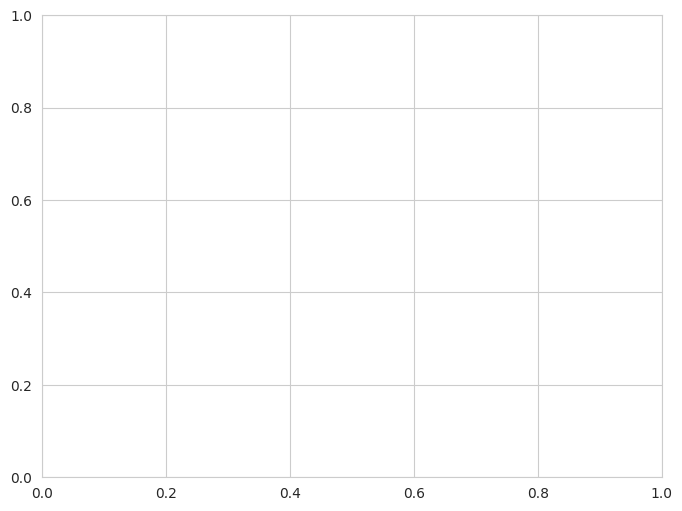

In [ ]:
# ===== 4. Plotar =====
plt.figure(figsize=(8, 6))
plt.pcolormesh(xx, yy, Z_cores, shading='auto', alpha=0.3)

# Plotar pontos reais
for classe in y.unique():
    plt.scatter(
        X[y == classe]['transacoes'],
        X[y == classe]['total_valor'],
        label=classe,
        edgecolor='k'
    )

plt.xlabel("Transações")
plt.ylabel("Valor total (R$)")
plt.title("Limites de Decisão - Classificação de Maturidade")
plt.legend()
plt.show()